# **Algoritmo de segmentación**

La idea principal del algoritmo de aprendizaje automático en **Agrotrace** es poder clasificar la fruta en *fresca* o *podrida*, sin embargo hay un problema que puede surgir cuando el modelo se incorpore al microservicio de inteligencia artificial y, posteriormente, se conecte al backend principal para retornar su inferencia y son las imagenes que lleguen en el ambiente de producción.

Para entrenar el modelo de visión artificial que clasifica el estado de la fruta a publicar usamos datasets públicos, en los que cada imagen encuadra perfectamente la fruta. Esto permite que el modelo capte la mayor cantidad posible de patrones (color, textura, manchas, etc.). Sin embargo, las fotos que suba el agricultor en producción difícilmente tendrán ese encuadre: pueden incluir fondo, otras frutas, manos u objetos alrededor. Exigirle al agricultor que tome la foto con un encuadre tan preciso haría que la plataforma perdiera usabilidad.

Por eso necesitamos un modelo previo que **detecte en qué parte de la imagen está la fruta**, para luego recortar la imagen exactamente a ese recuadro (*bounding box*) y entregarle al clasificador una entrada similar a la que vio durante el entrenamiento.


## **1. Instalación de dependencias**

Instalamos algunas librerias que necesitamos y no vienen instaladas en el entorno de Google Colab por defecto. En este caso:

* **ultralytics:** es un paquete que permite integrar modelos YOLO en Python para detección de objetos, segmentación, clasificación, seguimiento y estimación de profundidad.
* **openCV:** es una biblioteca de código abierto de visión por computadora y procesamiento de imágenes y video en tiempo real.

In [1]:
!pip install ultralytics
!pip install opencv-python

## **2. Importaciones**

Importamos todas las librerias necesarias para la carga y experimentación con el modelo de segmentación.

In [2]:
import math
import os
import time

import cv2
import matplotlib.pyplot as plt
from google.colab import drive
from google.colab.patches import cv2_imshow
from ultralytics import YOLOE

## **3. Montaje de Google Drive**

Estos experimentos se están realizando en Visual Studio Code mediante la extensión oficial de Google Colaboratory ya que nos permite conectarnos a un entorno de ejecución remoto de Colab sin salir del editor, aprovechando sus recursos de cómputo y las librerías que ya trae preinstaladas, mientras conservamos el notebook versionado junto al resto del repositorio de **Agrotrace**.

Como el entorno de ejecución es remoto, no tiene acceso a los archivos de nuestra máquina local. Por eso montamos Google Drive, donde están guardadas las imágenes de prueba de las frutas y donde también se almacenarán los resultados (imágenes anotadas y recortes) que genere el modelo.

In [3]:
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Para la primera prueba, vamos a experimentar directamente con una imagen de una papaya para ver si el modelo en su versión base y con las clases que se describen en la documentación (frutas que reconoce) puede dibujar un bounding box segmentando el lugar de la fotografía donde se encuentra.

In [4]:
image = "/content/drive/MyDrive/agrotrace/Papaya.png"

## **4. Carga del modelo**

Para este caso cargaremos la arquitectura de solo detección (sin cabeza de máscaras), esta se carga con el yaml de detección y se le transfieren los pesos del modelo -seg. Así el modelo solo calcula bounding boxes y no pierde tiempo generando máscaras.

> **NOTA:** Esta se desición se toma gracias ya que el modelo (junto a su microservicio) se ejecutará en una instancia de AWS sin una GPU que pueda acelerar su inferencia, por lo tanto es muy importante eliminar las operaciones innecesarias que puedan elevar el tiempo de respuesta de nuestro microservicio.

In [5]:
model = YOLOE("yoloe-26s.yaml").load("yoloe-26s-seg.pt")
model.set_classes(["fruit", "apple", "banana", "orange", "mango"])

Transferred 822/822 items from pretrained weights


Procedemos a hacer inferencia con la imagen de ejemplo

In [6]:
start = time.perf_counter()
results = model.predict(image, device="cpu", agnostic_nms=True)
cajas = results[0].boxes.xyxy
elapsed_ms = (time.perf_counter() - start) * 1000

for c in cajas:
    print(c)

# speed: tiempos (ms) que reporta ultralytics por etapa
print(f"Tiempo total: {elapsed_ms:.1f} ms | {results[0].speed}")


image 1/1 /content/drive/MyDrive/agrotrace/Papaya.png: 480x640 1 orange, 418.8ms
Speed: 8.6ms preprocess, 418.8ms inference, 4.7ms postprocess per image at shape (1, 3, 480, 640)
tensor([ 409.1249,  379.2985, 1072.4149,  721.8564])
Tiempo total: 674.3 ms | {'preprocess': 8.588231001340318, 'inference': 418.8382020001882, 'postprocess': 4.680783000367228}


Veamos la imagen con el bounding box dibujado.

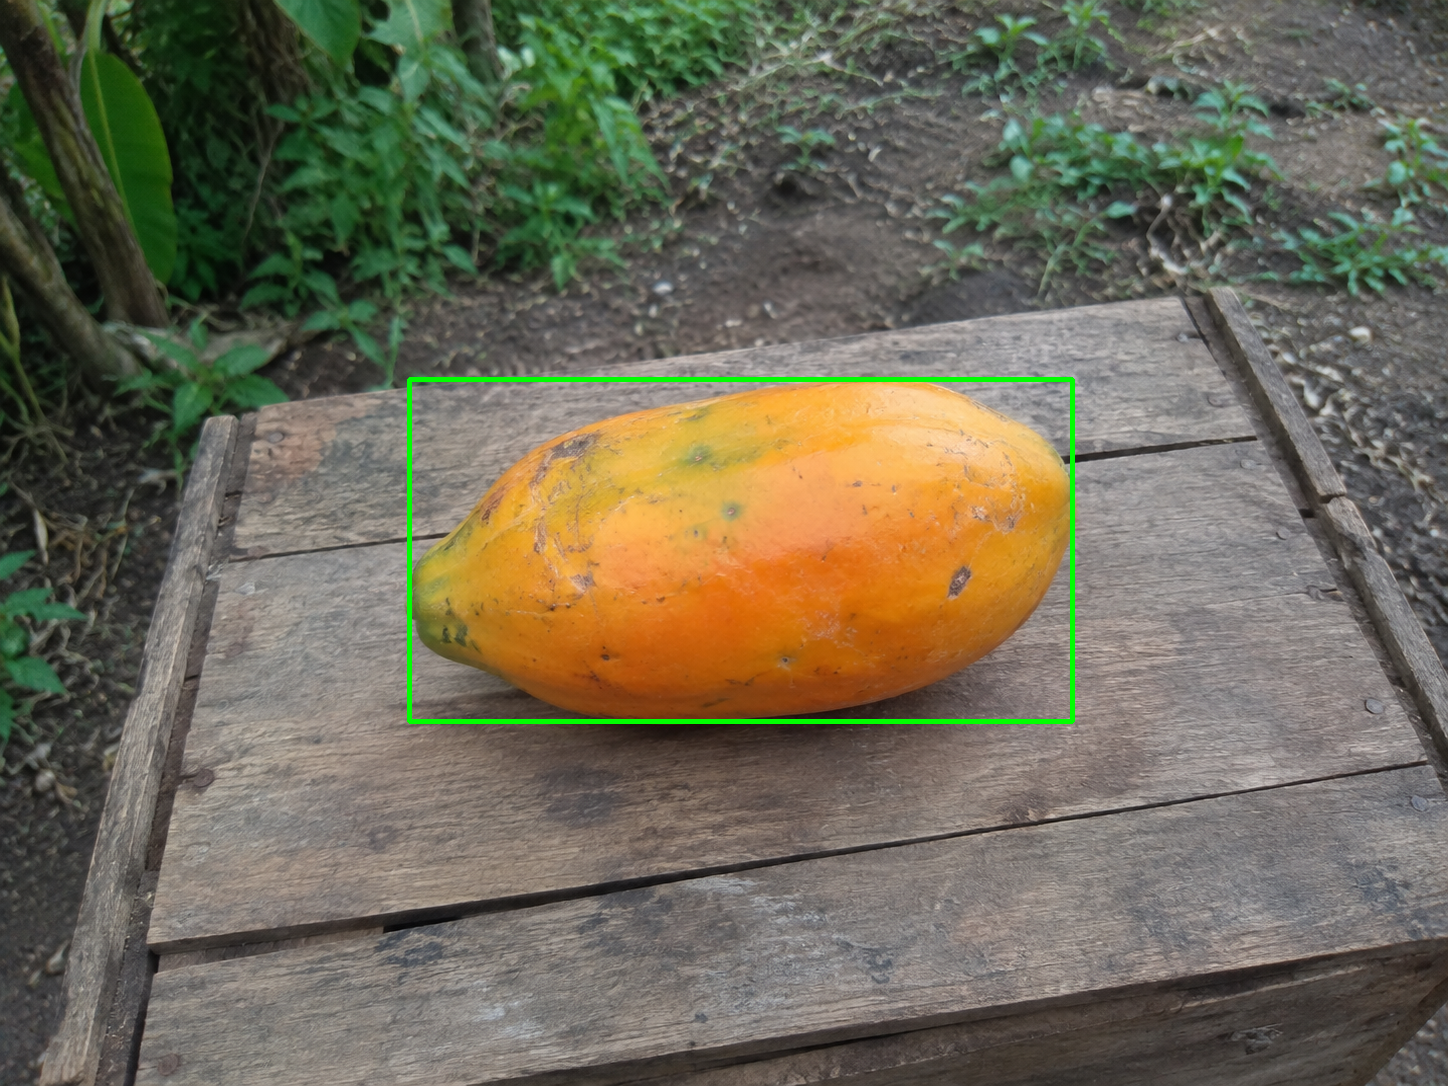

In [7]:
img = results[0].orig_img.copy()  # imagen original (BGR)

for c in cajas:
    x1, y1, x2, y2 = c.int().tolist()
    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)  # solo la caja, sin etiqueta

cv2.imwrite("resultado.jpg", img)
cv2_imshow(img)

Ahora podemos extraer las coordenadas y recortar la imagen, generando un frame en el que solo aparezca la fruta.

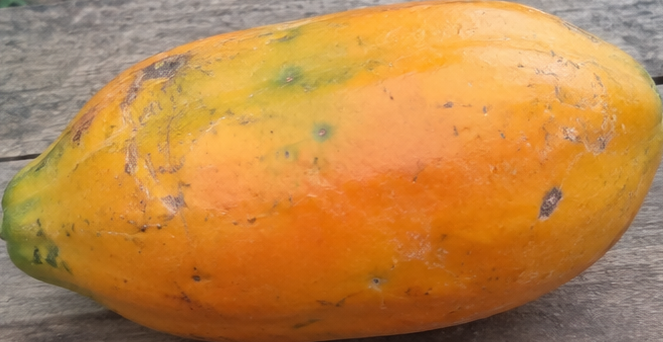

In [8]:
r = results[0]
best = r.boxes.conf.argmax()  # detección con mayor confianza
x1, y1, x2, y2 = r.boxes.xyxy[best].int().tolist()

crop = r.orig_img[y1:y2, x1:x2]

cv2.imwrite("recorte.jpg", crop)
cv2_imshow(crop)

## **5. Prueba con todas las frutas**

Basandonos en la idea principal para la que queremos emplear visión artificial en **agrotrace**, el mejor dataset público que cumple con los requerimientos de nuestra plataforma es [Fruit Quality Datasets (FruQ-DB)](https://zenodo.org/records/7224690?preview_file=FruQ-DB.zip). Este dataset cuenta con 10 tipos de frutas:

* Avocado (Aguacate)
* Banana (Banano)
* Cucumber (Pepino)
* Kaki (Caqui)
* Papaya (Papaya)
* Peach (Durazno)
* Pepper (Pimiento)
* Strawberry (Fresa)
* Tomato (Tomate)
* Watermelon (Sandía)

Estos 10 tipos de frutas se agrupan en 3 clases: `Fresh`, `Mild`, `Rotten`. En las siguientes celdas experimentamos para ver si Yolo 26 s es capaz de segmentar las frutas que tenemos en este dataset.Por cada fruta se guarda en `OUTPUT_DIR` la imagen anotada (bounding boxes) y el recorte de la detección con mayor confianza, y se mide cuánto demoró la inferencia. Al final se imprime un resumen.

Definimos las rutas y creamos la carpeta de output.

In [10]:
IMAGES_DIR = "/content/drive/MyDrive/agrotrace"
OUTPUT_DIR = os.path.join(IMAGES_DIR, "segmentation_results")
os.makedirs(OUTPUT_DIR, exist_ok=True)

Lista de frutas que vamos a procesar con el modelo.

In [11]:
FRUITS = [
    "Avocado",
    "banana",
    "cucumber",
    "Kaki",
    "Papaya",
    "Peach",
    "pepper",
    "Strawberry",
    "Tomatoe",
    "watermelon",
]

Definimos una lista con las clases (en inglés) que se le pasan al modelo como prompt de texto

In [12]:
CLASSES = [
    "fruit",
    "avocado",
    "banana",
    "cucumber",
    "persimmon",
    "papaya",
    "peach",
    "pepper",
    "strawberry",
    "tomato",
    "watermelon",
]

Seteamos el modelos con las clases

In [13]:
model.set_classes(CLASSES)

Creamos una función para encontrar las imagenes en la ruta de `IMAGES_DIR` que definimos previamente, cada archivo tiene el nombre de la fruta que definimos en la lista y tiene extensión `.png`

In [14]:
def find_image(fruit):
    """Busca <fruit>.png en IMAGES_DIR sin importar mayúsculas/minúsculas."""
    target = f"{fruit}.png".lower()
    for name in os.listdir(IMAGES_DIR):
        if name.lower() == target:
            return os.path.join(IMAGES_DIR, name)
    return None

Ahora generamos un loop donde se busque la imagen, la procesemos con el modelo de segmentación y retornemos la imagen con los bounding boxes encontrados por este

In [15]:
summary = []
plots = {}  

for fruit in FRUITS:
    path = find_image(fruit)
    if path is None:
        print(f"[{fruit}] imagen no encontrada en {IMAGES_DIR}")
        summary.append((fruit, "no encontrada", 0, None, None))
        continue

    start = time.perf_counter()
    # agnostic_nms: las cajas no se separan por clase, solo nos interesa dónde está la fruta
    r = model.predict(path, device="cpu", agnostic_nms=True, verbose=False)[0]
    elapsed_ms = (time.perf_counter() - start) * 1000  # incluye lectura de la imagen
    detections = len(r.boxes)

    img = r.orig_img.copy()  # imagen original (RGB)
    for c in r.boxes.xyxy:
        x1, y1, x2, y2 = c.int().tolist()
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)  # solo la caja, sin etiqueta
    plots[fruit] = img
    cv2.imwrite(os.path.join(OUTPUT_DIR, f"{fruit}_detectado.jpg"), img)

    if detections == 0:
        print(f"[{fruit}] sin detecciones ({elapsed_ms:.1f} ms)")
        summary.append((fruit, "sin detecciones", 0, None, elapsed_ms))
        continue

    best = r.boxes.conf.argmax()  # solo tomamos la detección con mayor confianza
    x1, y1, x2, y2 = r.boxes.xyxy[best].int().tolist()
    conf = float(r.boxes.conf[best])

    crop = r.orig_img[y1:y2, x1:x2]
    cv2.imwrite(os.path.join(OUTPUT_DIR, f"{fruit}_recorte.jpg"), crop)

    # Imprimimos un resumen de la detección y los tiempos por etapa
    print(
        f"[{fruit}] {detections} detecciones, mejor caja: ({x1}, {y1}, {x2}, {y2}) conf {conf:.2f} "
        f"- {elapsed_ms:.1f} ms (pre {r.speed['preprocess']:.1f}, "
        f"inf {r.speed['inference']:.1f}, post {r.speed['postprocess']:.1f})"
    )
    summary.append((fruit, "ok", detections, conf, elapsed_ms))

[Avocado] 1 detecciones, mejor caja: (601, 355, 923, 784) conf 0.56 - 619.2 ms (pre 5.1, inf 394.8, post 1.0)
[banana] 1 detecciones, mejor caja: (476, 383, 1066, 701) conf 0.91 - 491.3 ms (pre 4.9, inf 412.7, post 1.4)
[cucumber] 1 detecciones, mejor caja: (508, 429, 977, 759) conf 0.88 - 747.7 ms (pre 7.4, inf 626.4, post 1.4)
[Kaki] 1 detecciones, mejor caja: (542, 364, 948, 753) conf 0.78 - 698.3 ms (pre 7.7, inf 604.0, post 1.5)
[Papaya] 1 detecciones, mejor caja: (408, 379, 1073, 721) conf 0.70 - 723.7 ms (pre 7.6, inf 615.9, post 1.1)
[Peach] 1 detecciones, mejor caja: (569, 352, 983, 766) conf 0.47 - 690.0 ms (pre 8.0, inf 597.9, post 1.2)
[pepper] 1 detecciones, mejor caja: (505, 366, 911, 819) conf 0.66 - 740.7 ms (pre 7.8, inf 624.4, post 1.2)
[Strawberry] 1 detecciones, mejor caja: (601, 459, 886, 782) conf 0.82 - 657.9 ms (pre 7.4, inf 551.9, post 0.9)
[Tomatoe] 1 detecciones, mejor caja: (564, 394, 921, 744) conf 0.44 - 513.4 ms (pre 4.8, inf 409.4, post 0.9)
[watermelon]

### **Resumen**

Presentamos los resultados de la etapa anterior para ver que frutas pudieron ser segmentadas con éxito

In [16]:
print(f"{'Fruta':<12} {'Estado':<16} {'Det.':>4}  {'Conf.':>5}  {'Tiempo (ms)':>11}")
for fruit, status, detections, conf, elapsed_ms in summary:
    conf_text = f"{conf:.2f}" if conf is not None else "-"
    time_text = f"{elapsed_ms:.1f}" if elapsed_ms is not None else "-"
    print(f"{fruit:<12} {status:<16} {detections:>4}  {conf_text:>5}  {time_text:>11}")

segmented = sum(1 for s in summary if s[1] == "ok")
times = [s[4] for s in summary if s[4] is not None]
print(f"Detectadas: {segmented}/{len(FRUITS)}")
if times:
    # La primera inferencia suele ser más lenta (calentamiento del modelo)
    print(f"Tiempo promedio por inferencia: {sum(times) / len(times):.1f} ms")
    print(f"Tiempo mín / máx: {min(times):.1f} / {max(times):.1f} ms")
print(f"Resultados guardados en: {OUTPUT_DIR}")

Fruta        Estado           Det.  Conf.  Tiempo (ms)
Avocado      ok                  1   0.56        619.2
banana       ok                  1   0.91        491.3
cucumber     ok                  1   0.88        747.7
Kaki         ok                  1   0.78        698.3
Papaya       ok                  1   0.70        723.7
Peach        ok                  1   0.47        690.0
pepper       ok                  1   0.66        740.7
Strawberry   ok                  1   0.82        657.9
Tomatoe      ok                  1   0.44        513.4
watermelon   ok                  1   0.71        498.7
Detectadas: 10/10
Tiempo promedio por inferencia: 638.1 ms
Tiempo mín / máx: 491.3 / 747.7 ms
Resultados guardados en: /content/drive/MyDrive/agrotrace/segmentation_results


### **Visualización de los bounding boxes**

Por último, visualicemos las imagenes originales con sus respectivos bounding boxes.

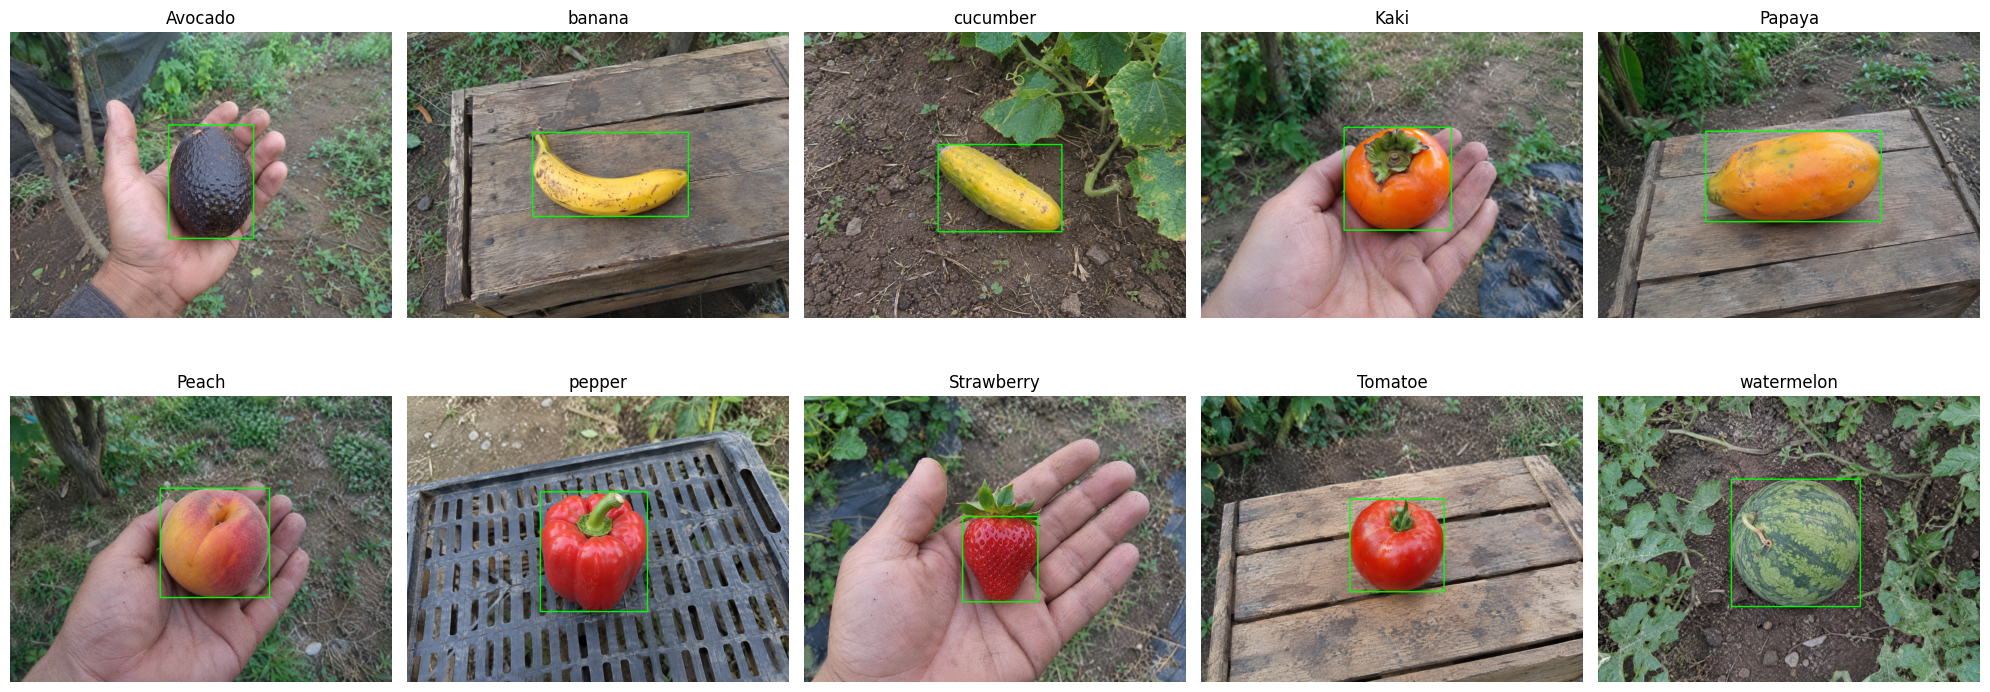

In [18]:
cols = 5
rows = math.ceil(len(plots) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows), squeeze=False)

for ax in axes.flat:
    ax.axis("off")

for ax, (fruit, img) in zip(axes.flat, plots.items()):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))  # OpenCV usa BGR, matplotlib RGB
    ax.set_title(fruit)

plt.tight_layout()
plt.show()